In [5]:
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from vae import MissingValueVAE
from vae import get_latent_embeddings
import random

In [6]:
fundamentals = joblib.load("../../data/03_gold/fundamentals.pkl")
train_ticks = fundamentals['X_train']['EntityCode']
data = joblib.load("../../data/03_gold/testset_scaled.pkl")
usable_features = data["usable_features"]
X_test  = data["X_test_scaled"]
X_test_mask = data["X_test_mask"]
X_test_EntityCodes = data["X_test_EntityCodes"]
X_test_EntityCodes

array(['0010.HK', '0021.HK', '0028.HK', ..., 'ZTS', 'ZUC.MI', 'ZV.MI'],
      dtype=object)

In [7]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# 1. Modellarchitektur neu instanziieren (exakt wie im train_vae)
model = MissingValueVAE(
    num_features=X_test.shape[1],  # Anzahl deiner Features
    emb_dim=8,                             # Muss mit dem Trainingscode übereinstimmen!
    hidden_dims=(512, 256, 128, 64),
    latent_dim=16,
    dropout_rate=0.1
).to(device)

# 2. Die gespeicherten Gewichte laden
state_dict = torch.load("parameters\\vae_16_0.01_0.1_40.pt", map_location=device, weights_only=True)
model.load_state_dict(state_dict)

# 3. Modell in den Evaluierungsmodus versetzen
model.eval()

# 4. Jetzt erst an get_latent_embeddings übergeben:
embeddings_test = get_latent_embeddings(model, X_test, X_test_mask, device=device)

In [8]:
len(embeddings_test[0])

16

In [9]:
import pandas as pd
import yfinance as yf


def fetch_weekly_close_prices(ticker_list):
    """Lädt wöchentliche Schlusskurse für eine Liste von Tickern herunter."""
    # yfinance lädt alle Ticker parallel
    df = yf.download(
        ticker_list,
        interval="1wk",
        start="2024-01-01",     
        end="2026-09-17",
        auto_adjust=True,
        keepna=True,
        prepost=False,
        progress=False,
    )

    # MultiIndex / Single-Ticker Absicherung für Spaltenzugriff
    if isinstance(df.columns, pd.MultiIndex):
        close_prices = df["Close"].copy()
    else:
        close_prices = df[["Close"]].copy()

    return close_prices


def prepare_weekly_returns(close_prices, max_nan_pct=0.01):
    """Säubert Preiszeitreihen und berechnet wöchentliche Renditen ohne künstliche 0%-Renditen."""
    # 1. Ticker filtern, die insgesamt zu viele fehlende Werte aufweisen
    max_allowed_nans = int(len(close_prices) * max_nan_pct)
    valid_tickers = close_prices.columns[
        close_prices.isna().sum() <= max_allowed_nans
    ]
    df_clean = close_prices[valid_tickers].copy()

    # 2. Nur in die Zukunft auffüllen (Vorwochenpreis übernehmen)
    # WICHTIG: Kein bfill(), um fiktive 0%-Renditen vor dem Börsenstart/Datenstart zu vermeiden
    df_filled = df_clean.ffill()

    # 3. Wöchentliche prozentuale Rendite berechnen
    returns = df_filled.pct_change()

    # Erste Zeile sowie Zeilen, in denen vor Startdatum noch NaN herrschte, verwerfen
    returns = returns.dropna(how="all")

    print(f"Eingangs-Ticker:          {close_prices.shape[1]}")
    print(f"Nutzbare Ticker nach Filter: {returns.shape[1]}")

    return returns


# Aufruf
close_prices = fetch_weekly_close_prices(X_test_EntityCodes.tolist())
print(len(close_prices.columns))
returns = prepare_weekly_returns(close_prices)
print(len(returns.columns))

$ALCAB.PA: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-17) (Yahoo error = "No data found, symbol may be delisted")
$LPRO: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-17)
$MLAST.PA: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-17) (Yahoo error = "No data found, symbol may be delisted")
$MLRSR.LS: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-17)
$EMGS.OL: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-17) (Yahoo error = "No data found, symbol may be delisted")
$EIFF.PA: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-17)
$SEFER.PA: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-17) (Yahoo error = "No data found, symbol may be delisted")
$TD.MI: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-17) (Yahoo error = "No data found, symbol may be delisted")
$NOTV: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09

1187
Eingangs-Ticker:          1187
Nutzbare Ticker nach Filter: 1074
1074


In [10]:
close_prices.reset_index().isna().sum().sort_values(ascending=False)

Ticker
LPRO        142
NOTV        142
MLBAR.PA    142
MLAST.PA    142
0638.HK     142
           ... 
ALHAF.PA      0
ALHGO.PA      0
ALHPI.PA      0
ALITL.PA      0
ZV.MI         0
Length: 1188, dtype: int64

In [10]:
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

sim_matrix = cosine_similarity(embeddings_test)
euc_matrix = euclidean_distances(embeddings_test)

# 2. In DataFrame verpacken mit Firmennamen als Index & Spalten
df_sim = pd.DataFrame(sim_matrix, index=X_test_EntityCodes, columns=X_test_EntityCodes)
df_euc = pd.DataFrame(euc_matrix, index=X_test_EntityCodes, columns=X_test_EntityCodes)


In [12]:
import numpy as np
import pandas as pd


def select_farthest_portfolio(
    dist_matrix: pd.DataFrame, available_companies: list, n_assets: int = 15
) -> list:
    """Wählt n_assets Firmen aus, die im Latent Space maximal zueinander beabstandet sind

    (Farthest Point Sampling / Greedy Max-Min Diversity), gefiltert nach einer
    Liste verfügbarer Firmen (available_companies).
    """
    # 1. Schnittmenge bilden: Nur Firmen behalten, die in der Distanzmatrix UND in available_companies vorkommen
    valid_companies = [
        c for c in dist_matrix.index if c in set(available_companies)
    ]

    if len(valid_companies) < n_assets:
        raise ValueError(
            f"Nur {len(valid_companies)} übereinstimmende Unternehmen verfügbar, "
            f"aber {n_assets} angefordert."
        )

    # Distanzmatrix auf die gültigen Unternehmen beschränken
    sub_dist_df = dist_matrix.loc[valid_companies, valid_companies]
    matrix = sub_dist_df.values
    companies = sub_dist_df.index.tolist()

    # 2. Starte mit dem Paar, das die absolut größte Distanz im gefilterten Raum hat
    first_pair_idx = np.unravel_index(np.argmax(matrix), matrix.shape)
    selected_indices = [first_pair_idx[0], first_pair_idx[1]]

    # 3. Füge schrittweise die Firma hinzu, deren minimaler Abstand zu den bereits
    #    gewählten Firmen am größten ist (Max-Min Kriterium)
    while len(selected_indices) < n_assets:
        # Distanzen aller Firmen zu den bereits ausgewählten Firmen
        sub_matrix = matrix[:, selected_indices]

        # Für jede Firma den Mindestabstand zur nächsten bereits gewählten Firma finden
        min_distances_to_selected = np.min(sub_matrix, axis=1)

        # Bereits gewählte Firmen maskieren (Distanzen auf -1 setzen)
        min_distances_to_selected[selected_indices] = -1

        # Die Firma mit dem größten Mindestabstand auswählen
        next_idx = np.argmax(min_distances_to_selected)
        selected_indices.append(next_idx)

    return [companies[i] for i in selected_indices]
# Portfolio aus den 30 am stärksten diversifizierten Firmen extrahieren
vae_portfolio_30 = select_farthest_portfolio(df_euc, returns.columns, n_assets=15)

print(f"Ausgewählte VAE-Aktien ({len(vae_portfolio_30)}):")
print(vae_portfolio_30)

Ausgewählte VAE-Aktien (15):
['C', 'ICU', 'GOOGL', 'NRG', '0588.HK', 'PRMB', 'FORE.PA', 'BLC.PA', 'FCNCA', 'SIFG.AS', 'LUCD', 'OPAL', 'GNE', 'KEX', 'GTX']


In [11]:
import numpy as np
import pandas as pd
from typing import Optional


def select_farthest_portfolio_rand(
    dist_matrix: pd.DataFrame, 
    available_companies: list, 
    n_assets: int = 15,
    random_state: Optional[int] = None
) -> list:
    """Wählt n_assets Firmen aus, die im Latent Space maximal zueinander beabstandet sind
    (Farthest Point Sampling / Greedy Max-Min Diversity).

    Wenn random_state gesetzt ist, wird die Startfirma zufällig gewählt.
    """
    # 1. Schnittmenge bilden
    valid_companies = [
        c for c in dist_matrix.index if c in set(available_companies)
    ]

    if len(valid_companies) < n_assets:
        raise ValueError(
            f"Nur {len(valid_companies)} übereinstimmende Unternehmen verfügbar, "
            f"aber {n_assets} angefordert."
        )

    # Distanzmatrix beschränken
    sub_dist_df = dist_matrix.loc[valid_companies, valid_companies]
    matrix = sub_dist_df.values
    companies = sub_dist_df.index.tolist()

    # Random Generator initialisieren
    rng = np.random.default_rng(random_state)

    # 2. Start-Strategie festlegen:
    if random_state is not None:
        # A) Zufällige erste Firma auswählen
        first_idx = rng.choice(len(companies))
        
        # B) Die zweite Firma ist diejenige mit der größten Distanz zur ersten
        second_idx = np.argmax(matrix[first_idx])
        selected_indices = [first_idx, second_idx]
    else:
        # C) Determinastisch: Das Paar mit der absolut größten Distanz
        first_pair_idx = np.unravel_index(np.argmax(matrix), matrix.shape)
        selected_indices = [first_pair_idx[0], first_pair_idx[1]]

    # 3. Schrittweise weitere Firmen hinzufügen (Max-Min Kriterium)
    while len(selected_indices) < n_assets:
        # Distanzen aller Firmen zu den bereits ausgewählten Firmen
        sub_matrix = matrix[:, selected_indices]

        # Für jede Firma den Mindestabstand zur nächsten bereits gewählten Firma finden
        min_distances_to_selected = np.min(sub_matrix, axis=1)

        # Bereits gewählte Firmen maskieren (Distanzen auf -1 setzen)
        min_distances_to_selected[selected_indices] = -1.0

        # Die Firma mit dem größten Mindestabstand auswählen
        next_idx = np.argmax(min_distances_to_selected)
        selected_indices.append(next_idx)

    return [companies[i] for i in selected_indices]

vae_portfolio_30_rand = select_farthest_portfolio_rand(df_euc, returns.columns, n_assets=2, random_state=10)

print(f"Ausgewählte VAE-Aktien ({len(vae_portfolio_30_rand)}):")
print(vae_portfolio_30_rand)
vae_portfolio = []
for i in range(1001):
    portfolio = select_farthest_portfolio_rand(df_euc, returns.columns, n_assets=2, random_state=i)
    vae_portfolio.append(portfolio)

Ausgewählte VAE-Aktien (2):
['OGN', 'NXDT']


In [12]:
import numpy as np
import pandas as pd


def calculate_portfolio_diversification_ratio(
    returns: pd.DataFrame,
    tickers: list = None,
    num_assets: int = 2,
    random_state: int = None,
):
    """Berechnet die Diversification Ratio für ein gleichgewichtetes Portfolio.

    Parameters:
    -----------
    returns : pd.DataFrame
        DataFrame mit Renditen (Spalten = Ticker).
    tickers : list, optional
        Spezifische Liste von Tickern/EntityCodes für das Portfolio.
        Falls None, werden zufällig `num_assets` Ticker gezogen.
    num_assets : int, default 30
        Anzahl der zufällig zu ziehenden Ticker (nur relevant, wenn `tickers=None`).
    random_state : int, optional
        Seed für die zufällige Titelauswahl zur Reproduzierbarkeit.
    """
    if tickers is not None:
        # Prüfen, ob alle angegebenen Ticker im Returns-DataFrame existieren
        missing_tickers = [t for t in tickers if t not in returns.columns]
        if missing_tickers:
            raise ValueError(
                f"Die folgenden Ticker befinden sich nicht in den Returns-Daten: {missing_tickers}"
            )
        selected_tickers = list(tickers)
        actual_num_assets = len(selected_tickers)
    else:
        if random_state is not None:
            np.random.seed(random_state)

        available_tickers = returns.columns
        if len(available_tickers) < num_assets:
            raise ValueError(
                f"Zu wenige Ticker vorhanden ({len(available_tickers)}) für ein {num_assets}-Werte-Portfolio."
            )

        selected_tickers = np.random.choice(
            available_tickers, size=num_assets, replace=False
        ).tolist()
        actual_num_assets = num_assets

    portfolio_returns = returns[selected_tickers]

    # Kovarianzmatrix (Σ) und Einzelvolatilitäten (σ) auf Jahresbasis (52 Wochen)
    cov_matrix_annual = portfolio_returns.cov() * 52
    volatilities_annual = portfolio_returns.std() * np.sqrt(52)

    # Gleichgewichtung (1 / N)
    weights = np.ones(actual_num_assets) / actual_num_assets

    # Gewichtiges Mittel der Einzelvolatilitäten (Zähler)
    weighted_vol_sum = np.dot(weights, volatilities_annual)

    # Portfolio-Gesamtvolatilität (Nenner)
    portfolio_variance = np.dot(weights.T, np.dot(cov_matrix_annual, weights))
    portfolio_volatility = np.sqrt(portfolio_variance)

    # Diversification Ratio
    diversification_ratio = weighted_vol_sum / portfolio_volatility

    return {
        "diversification_ratio": diversification_ratio,
        "portfolio_volatility_annual": portfolio_volatility,
        "weighted_avg_volatility_annual": weighted_vol_sum,
        "selected_tickers": selected_tickers,
    }

print(calculate_portfolio_diversification_ratio(returns, vae_portfolio_30_rand))
print(calculate_portfolio_diversification_ratio(returns))
drs = []
for i in range(1000):
    res = calculate_portfolio_diversification_ratio(returns)
    dr = res['diversification_ratio']
    drs.append(dr)
print("Random", np.mean(drs))
drs2 = []
for portfolio in vae_portfolio:
    res = calculate_portfolio_diversification_ratio(returns, portfolio)
    dr = res['diversification_ratio']
    drs2.append(dr)
print("VAE", np.mean(drs2))

{'diversification_ratio': 1.3244005879444305, 'portfolio_volatility_annual': 0.382332593912145, 'weighted_avg_volatility_annual': 0.5063615121675641, 'selected_tickers': ['OGN', 'NXDT']}
{'diversification_ratio': 1.356011058239926, 'portfolio_volatility_annual': 0.1223638154014886, 'weighted_avg_volatility_annual': 0.1659266868128475, 'selected_tickers': ['LI.PA', 'IBS.LS']}
Random 1.3013352765839585
VAE 1.2683724589563963


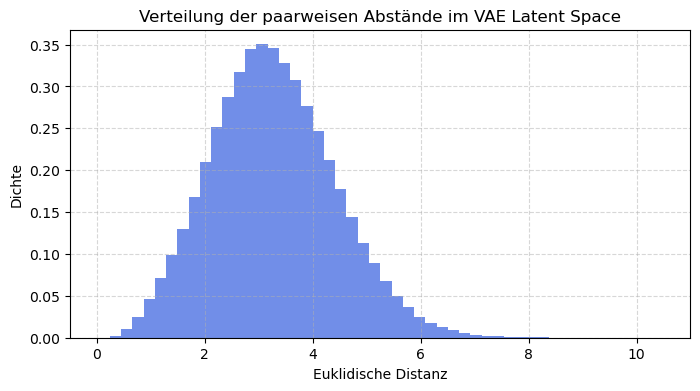

In [14]:
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist

# Paarweise euklidische Distanzen aller Aktien im Latent Space berechnen
latent_dists = pdist(embeddings_test, metric="euclidean")

plt.figure(figsize=(8, 4))
plt.hist(latent_dists, bins=50, density=True, alpha=0.75, color="royalblue")
plt.title("Verteilung der paarweisen Abstände im VAE Latent Space")
plt.xlabel("Euklidische Distanz")
plt.ylabel("Dichte")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Berechne t-SNE Projektion...


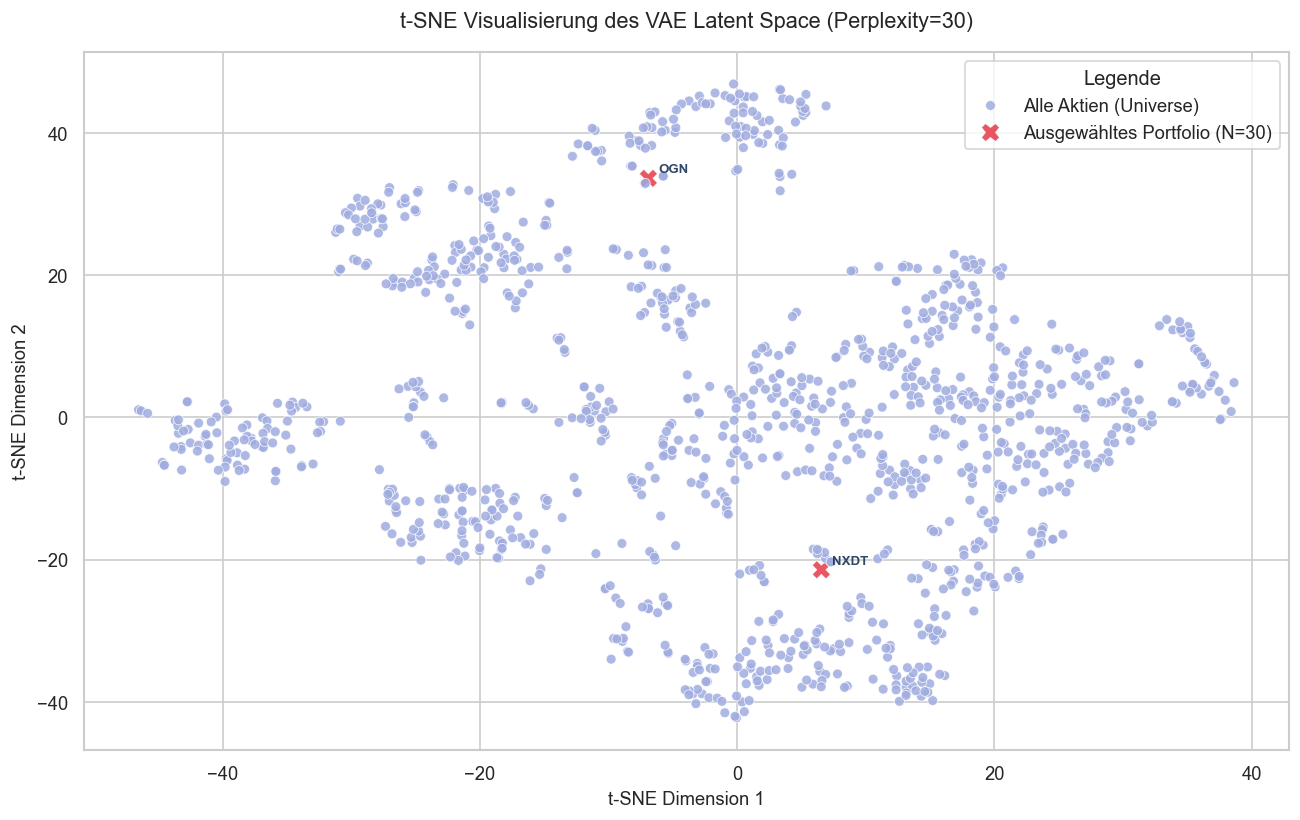

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.manifold import TSNE


def plot_tsne_latent_space(
    embeddings: np.ndarray,
    entity_codes: list,
    selected_portfolio_tickers: list = None,
    perplexity: int = 30,
    random_state: int = 42,
):
    """Erstellt einen 2D t-SNE Scatterplot der Latent Embeddings.

    Parameters:
    -----------
    embeddings : np.ndarray
        Die VAE Latent Embeddings (Shape: N_samples x Latent_Dim)
    entity_codes : list
        Liste der zugehörigen Ticker / EntityCodes
    selected_portfolio_tickers : list, optional
        Liste von Tickern (z.B. deine 30 VAE-Aktien), die im Plot hervorgehoben
        werden sollen
    perplexity : int, default 30
        t-SNE Parameter (typisch zwischen 5 und 50, bestimmt die Berücksichtigung
        lokaler vs. globaler Strukturen)
    random_state : int, default 42
        Seed für Reproduzierbarkeit
    """
    print("Berechne t-SNE Projektion...")
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=random_state,
        init="pca",
        learning_rate="auto",
    )
    embeddings_2d = tsne.fit_transform(embeddings)

    # DataFrame für einfaches Plotten erstellen
    df_tsne = pd.DataFrame(
        {
            "TSNE_1": embeddings_2d[:, 0],
            "TSNE_2": embeddings_2d[:, 1],
            "Ticker": entity_codes,
            "Type": "Alle Aktien (Universe)",
        }
    )

    # Falls ein ausgewähltes Portfolio übergeben wurde, diese Aktien markieren
    if selected_portfolio_tickers is not None:
        selected_set = set(selected_portfolio_tickers)
        df_tsne.loc[df_tsne["Ticker"].isin(selected_set), "Type"] = (
            "Ausgewähltes Portfolio (N=30)"
        )

    # Styling & Visualisierung
    plt.figure(figsize=(11, 7), dpi=120)
    sns.set_theme(style="whitegrid")

    # Scatterplot zeichnen
    ax = sns.scatterplot(
        data=df_tsne,
        x="TSNE_1",
        y="TSNE_2",
        hue="Type",
        style="Type",
        palette={
            "Alle Aktien (Universe)": "#A0ACE0",
            "Ausgewähltes Portfolio (N=30)": "#E63946",
        },
        markers={
            "Alle Aktien (Universe)": "o",
            "Ausgewähltes Portfolio (N=30)": "X",
        },
        size="Type",
        sizes={
            "Alle Aktien (Universe)": 35,
            "Ausgewähltes Portfolio (N=30)": 120,
        },
        alpha=0.85,
    )

    # Optional: Ticker-Namen für die ausgewählten Portfolio-Aktien anzeigen
    if selected_portfolio_tickers is not None:
        df_selected = df_tsne[
            df_tsne["Type"] == "Ausgewähltes Portfolio (N=30)"
        ]
        for _, row in df_selected.iterrows():
            ax.text(
                row["TSNE_1"] + 0.8,
                row["TSNE_2"] + 0.8,
                row["Ticker"],
                fontsize=8,
                weight="bold",
                color="#1D3557",
                alpha=0.9,
            )

    plt.title(
        f"t-SNE Visualisierung des VAE Latent Space (Perplexity={perplexity})",
        fontsize=13,
        pad=15,
    )
    plt.xlabel("t-SNE Dimension 1", fontsize=11)
    plt.ylabel("t-SNE Dimension 2", fontsize=11)
    plt.legend(title="Legende", loc="best", frameon=True)
    plt.tight_layout()
    plt.show()


# --- Aufrufbeispiel ---
# embeddings_test: Deine VAE Latent Vectors
# X_test_EntityCodes: Deine Ticker-Liste
plot_tsne_latent_space(
    embeddings=embeddings_test,
    entity_codes=X_test_EntityCodes.tolist(),
    selected_portfolio_tickers=vae_portfolio_30_rand,  # Oder vae_kmeans_portfolio
    perplexity=30,
)